# Task 3 (Medium): Country-Wise Netflix Content Analysis
**Auspify Technologies | Data Analysis Using Python Internship**
**Intern:** Aarti Jamage

**Goal:** Analyze Netflix content availability across different countries.

**Workflow:** 1) Extract and clean country information → 2) Content count by country → 3) Top content-producing countries → 4) Charts and rankings → 5) Business insights

## Step 1: Extract and clean country information

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import os

sns.set_theme(style="whitegrid")
os.makedirs("../outputs/charts", exist_ok=True)

df = pd.read_csv("../data/netflix_cleaned.csv")
print("Total titles:", len(df))
print("Unique country values:", df["country"].nunique())
df["country"].head()

Total titles: 8787
Unique country values: 86


0    United States
1           France
2    United States
3           Brazil
4    United States
Name: country, dtype: str

In [2]:
# In this dataset each title has ONE country value (no comma-separated lists),
# so no splitting is needed. Check for stray commas and whitespace anyway.
print("Rows with multiple countries:", df["country"].str.contains(",").sum())
print("Rows with extra spaces:", (df["country"] != df["country"].str.strip()).sum())

# 'Unknown' was created in Task 1 for missing countries: exclude it from rankings
unknown = (df["country"] == "Unknown").sum()
known = df[df["country"] != "Unknown"].copy()
print(f"Titles with unknown country: {unknown} ({unknown / len(df):.1%})")
print(f"Titles used for the country analysis: {len(known)}")

Rows with multiple countries: 0
Rows with extra spaces: 0
Titles with unknown country: 287 (3.3%)
Titles used for the country analysis: 8500


**Note:** The 287 titles with an unknown country are excluded from rankings, so they do not appear as a fake "country". They stay in the dataset for other tasks.

## Step 2: Calculate content count by country

In [3]:
country_counts = known.groupby("country").size().sort_values(ascending=False)
summary = country_counts.to_frame("Titles")
summary["Share (%)"] = (summary["Titles"] / summary["Titles"].sum() * 100).round(1)
summary["Cumulative (%)"] = summary["Share (%)"].cumsum().round(1)
print("Countries with content:", len(summary))
summary.head(15)

Countries with content: 85


,Titles,Share (%),Cumulative (%)
country,,,
United States,3240,38.1,38.1
India,1056,12.4,50.5
United Kingdom,638,7.5,58.0
Pakistan,420,4.9,62.9
Canada,271,3.2,66.1
Japan,259,3.0,69.1
South Korea,214,2.5,71.6
France,213,2.5,74.1
Spain,182,2.1,76.2


## Step 3: Identify the top content-producing countries

In [4]:
top10 = summary.head(10)
print("Top 10 countries:")
top10

Top 10 countries:


,Titles,Share (%),Cumulative (%)
country,,,
United States,3240,38.1,38.1
India,1056,12.4,50.5
United Kingdom,638,7.5,58.0
Pakistan,420,4.9,62.9
Canada,271,3.2,66.1
Japan,259,3.0,69.1
South Korea,214,2.5,71.6
France,213,2.5,74.1
Spain,182,2.1,76.2


In [5]:
print(f"Top 1 country share : {top10['Share (%)'].iloc[0]}%")
print(f"Top 2 countries share: {top10['Titles'].iloc[:2].sum() / summary['Titles'].sum() * 100:.1f}%")
print(f"Top 10 countries share: {top10['Titles'].sum() / summary['Titles'].sum() * 100:.1f}%")
print("Countries with only 1 title:", (country_counts == 1).sum())
print("Countries with 5 or fewer titles:", (country_counts <= 5).sum())

Top 1 country share : 38.1%
Top 2 countries share: 50.5%
Top 10 countries share: 78.0%
Countries with only 1 title: 18
Countries with 5 or fewer titles: 33


## Step 4: Create charts and rankings

### 4a. Top 10 countries: horizontal bar chart

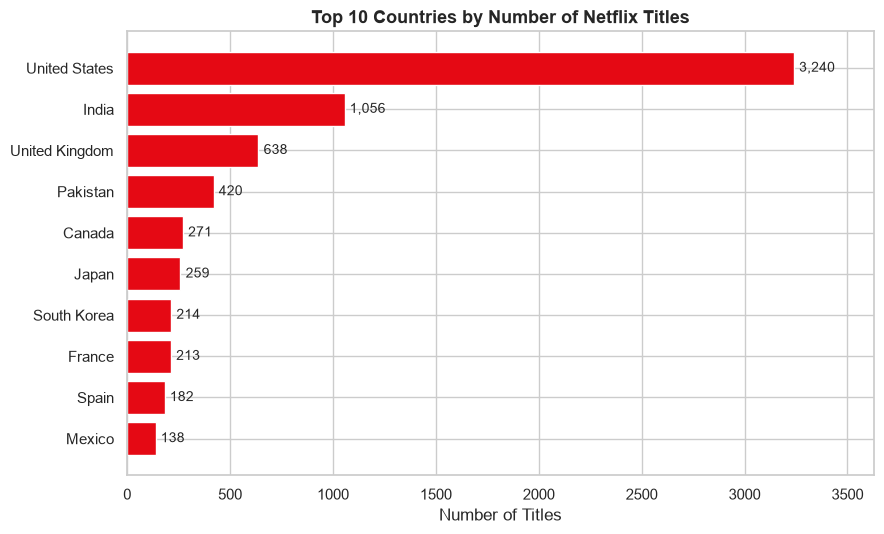

In [6]:
fig, ax = plt.subplots(figsize=(9, 5.5))
plot_df = top10.reset_index().sort_values("Titles")
bars = ax.barh(plot_df["country"], plot_df["Titles"], color="#E50914")
for b in bars:
    ax.text(b.get_width() + 25, b.get_y() + b.get_height() / 2, f"{int(b.get_width()):,}",
            va="center", fontsize=10)
ax.set_title("Top 10 Countries by Number of Netflix Titles", fontsize=13, fontweight="bold")
ax.set_xlabel("Number of Titles")
ax.set_ylabel("")
ax.set_xlim(0, plot_df["Titles"].max() * 1.12)
plt.tight_layout()
plt.savefig("../outputs/charts/task3_top10_countries.png", dpi=300, bbox_inches="tight")
plt.show()

### 4b. Movies vs TV Shows in the top 10 countries

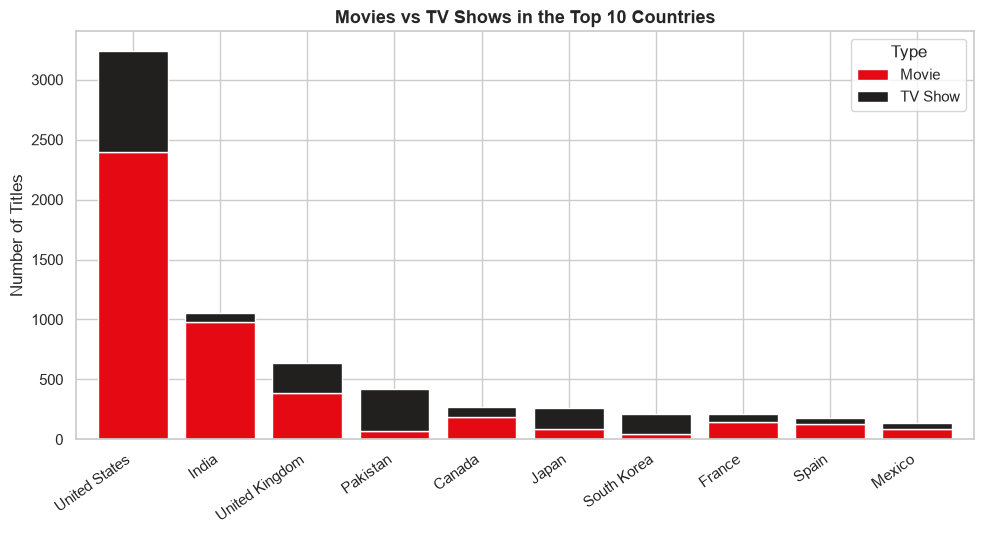

In [7]:
mix = pd.crosstab(known["country"], known["type"]).loc[top10.index]

fig, ax = plt.subplots(figsize=(10, 5.5))
mix.plot(kind="bar", stacked=True, color=["#E50914", "#221F1F"], ax=ax, width=0.8)
ax.set_title("Movies vs TV Shows in the Top 10 Countries", fontsize=13, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Number of Titles")
plt.xticks(rotation=35, ha="right")
ax.legend(title="Type")
plt.tight_layout()
plt.savefig("../outputs/charts/task3_top10_movies_vs_tv.png", dpi=300, bbox_inches="tight")
plt.show()

### 4c. TV Show share by country (countries with 100+ titles)

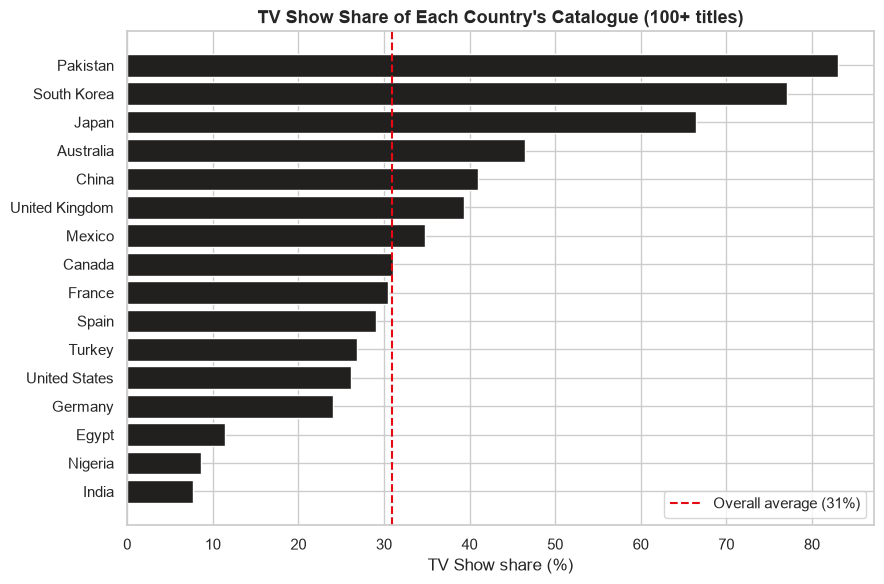

type,Movie,TV Show,Total,TV Show share (%)
country,,,,
Pakistan,71,349,420,83.1
South Korea,49,165,214,77.1
Japan,87,172,259,66.4
Australia,61,53,114,46.5
China,59,41,100,41.0
United Kingdom,387,251,638,39.3
Mexico,90,48,138,34.8
Canada,187,84,271,31.0
France,148,65,213,30.5


In [8]:
big = pd.crosstab(known["country"], known["type"])
big["Total"] = big.sum(axis=1)
big = big[big["Total"] >= 100].copy()
big["TV Show share (%)"] = (big["TV Show"] / big["Total"] * 100).round(1)
big = big.sort_values("TV Show share (%)")

overall_tv = (known["type"] == "TV Show").mean() * 100
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(big.index, big["TV Show share (%)"], color="#221F1F")
ax.axvline(overall_tv, color="#E50914", linestyle="--", label=f"Overall average ({overall_tv:.0f}%)")
ax.set_title("TV Show Share of Each Country's Catalogue (100+ titles)", fontsize=13, fontweight="bold")
ax.set_xlabel("TV Show share (%)")
ax.legend()
plt.tight_layout()
plt.savefig("../outputs/charts/task3_tv_share_by_country.png", dpi=300, bbox_inches="tight")
plt.show()
big.sort_values("TV Show share (%)", ascending=False)[["Movie", "TV Show", "Total", "TV Show share (%)"]]

### 4d. World map of content (interactive)

In [ ]:
try:
    map_df = country_counts.reset_index()
    map_df.columns = ["Country", "Titles"]
    fig = px.choropleth(map_df, locations="Country", locationmode="country names",
                        color="Titles", hover_name="Country", color_continuous_scale="Reds",
                        title="Netflix Titles by Country")
    fig.update_layout(margin=dict(l=0, r=0, t=50, b=0))
    fig.write_html("../outputs/charts/task3_world_map.html")
    fig.show()
except Exception as e:
    print("Map could not be drawn:", e)

### 4e. Ranking table

In [ ]:
ranking = summary.head(10).copy()
ranking.insert(0, "Rank", range(1, 11))
ranking.to_csv("../outputs/task3_country_ranking.csv")
ranking

,Rank,Titles,Share (%),Cumulative (%)
country,,,,
United States,1,3240,38.1,38.1
India,2,1056,12.4,50.5
United Kingdom,3,638,7.5,58.0
Pakistan,4,420,4.9,62.9
Canada,5,271,3.2,66.1
Japan,6,259,3.0,69.1
South Korea,7,214,2.5,71.6
France,8,213,2.5,74.1
Spain,9,182,2.1,76.2


## Step 5: Generate business insights

In [ ]:
# Recent content: where are the newest titles (2015 onwards) coming from?
recent = known[known["release_year"] >= 2015]["country"].value_counts().head(6)
recent

country
United States     2151
India              571
United Kingdom     459
Pakistan           364
Canada             217
South Korea        182
Name: count, dtype: int64

## Key findings and business insights

1. **Two markets dominate.** The United States (3,240 titles, 38.1%) and India (1,056, 12.4%) together account for about half of all titles with a known country (50.5%). The top 10 countries hold 78.0%.
2. **The catalogue has a long tail.** There are 85 countries with content, but 33 of them have 5 or fewer titles and 18 have just one. Netflix has token content in many markets rather than deep libraries.
3. **Content mix differs sharply by country.**
   - India is movie-heavy: only 7.7% of its titles are TV Shows. Nigeria (8.6%) and Egypt (11.4%) show the same pattern.
   - Pakistan (83.1%), South Korea (77.1%) and Japan (66.4%) lean strongly toward TV Shows, far above the 30% average.
4. **Asia is a growth story.** India, Pakistan, Japan and South Korea all rank in the top 10, and Pakistan, South Korea and Japan are TV-led. This supports investing in regional series for Asian audiences.
5. **Audience targeting differs by country.** In the top 10, Spain (81% Adults) and Mexico (75%) skew to mature content, while India (68% Teens) targets younger viewers.
6. **Recent production follows the same ranking.** For titles released since 2015, the order is the United States, India, the United Kingdom, Pakistan, Canada and South Korea, so the leaders are not being displaced.

**Business recommendations**
- Keep investing in the US and India, which anchor the catalogue.
- Grow TV Show libraries in movie-heavy markets such as India, Nigeria and Egypt, where series are under-represented.
- Use the success of Korean, Japanese and Pakistani series as a model for other emerging markets.
- Review the long tail: decide whether countries with 1 to 5 titles are strategic bets or low-value content.

**Limitation:** Each title has only one country, so co-productions are counted once, and 287 titles (3.3%) have no country information.